# Image Processing 1: Gaussian Blur and Colour Segmentation

**Part A** compares the run time of a Gaussian blur in the spatial domain and in the frequency
domain for sigma from 1 to 64.

**Part B** segments a teddy bear (with its shirt and ribbon) by thresholding in HSV space and
cleaning the mask with morphological operations, then finds the bounding box of the head and the
area and centre of each eye.

Built with scikit-image and SciPy
.

## A. Gaussian blur: spatial vs. frequency domain

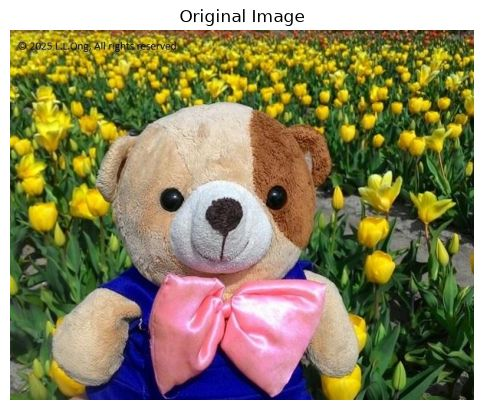

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from skimage import color, io

im = io.imread("teddy_bear.jpg")  # course image, not included in this repository

plt.imshow(im)
plt.title("Original Image")
plt.axis("off")
plt.show()

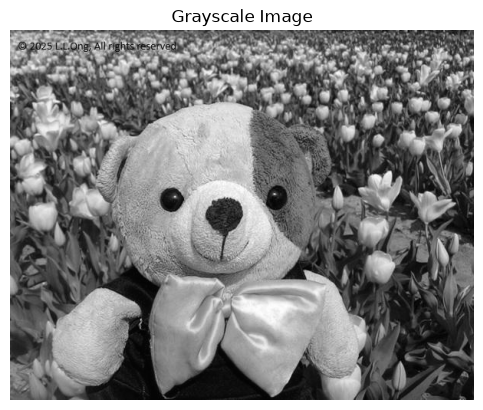

In [2]:
gray_im = color.rgb2gray(im)

plt.imshow(gray_im, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")
plt.show()

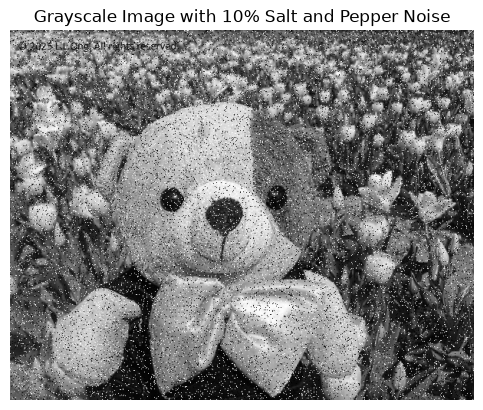

In [3]:
from skimage.util import random_noise

sp_noise_im = random_noise(gray_im, mode="s&p", amount=0.1)

plt.imshow(sp_noise_im, cmap="gray")
plt.title("Grayscale Image with 10% Salt and Pepper Noise")
plt.axis("off")
plt.show()

Spatial Times:   ['0.009', '0.010', '0.017', '0.025', '0.044', '0.090', '0.188']
Frequency Times: ['0.038', '0.038', '0.038', '0.037', '0.038', '0.037', '0.037']


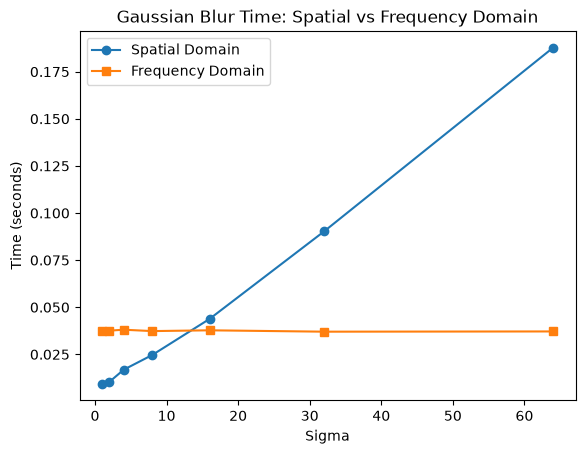

Max difference (sigma = 4, inner region): 0.0000


In [4]:
import time

import scipy.ndimage
from scipy.fft import fft2, fftfreq, ifft2
from skimage import img_as_float

float_im = img_as_float(gray_im)
sigma_values = [1, 2, 4, 8, 16, 32, 64]
N_TRIALS = 10  # every timing is the mean of 10 runs


def blur_spatial(image, sigma):
    return scipy.ndimage.gaussian_filter(image, sigma=sigma)


def blur_frequency(image, sigma):
    """Gaussian blur as a product in the frequency domain."""
    rows, cols = image.shape
    # Kernel of the image size with its centre at pixel (0, 0): fftfreq gives the signed distance
    # of every row/column from 0 in FFT order (0, 1, 2, ..., -2, -1)
    dr = fftfreq(rows, d=1 / rows)
    dc = fftfreq(cols, d=1 / cols)
    kernel = np.outer(np.exp(-dr**2 / (2 * sigma**2)), np.exp(-dc**2 / (2 * sigma**2)))
    kernel /= kernel.sum()  # keep the image brightness
    return ifft2(fft2(image) * fft2(kernel)).real


def mean_time(fn, sigma):
    start = time.perf_counter()
    for _ in range(N_TRIALS):
        fn(float_im, sigma)
    return (time.perf_counter() - start) / N_TRIALS


spatial_times = [mean_time(blur_spatial, s) for s in sigma_values]
frequency_times = [mean_time(blur_frequency, s) for s in sigma_values]

print("Spatial Times:  ", [f"{t:.3f}" for t in spatial_times])
print("Frequency Times:", [f"{t:.3f}" for t in frequency_times])

plt.plot(sigma_values, spatial_times, label="Spatial Domain", marker="o")
plt.plot(sigma_values, frequency_times, label="Frequency Domain", marker="s")
plt.title("Gaussian Blur Time: Spatial vs Frequency Domain")
plt.xlabel("Sigma")
plt.ylabel("Time (seconds)")
plt.legend()
plt.show()

# Both methods should give (almost) the same image away from the borders
diff = np.abs(blur_spatial(float_im, 4) - blur_frequency(float_im, 4))[40:-40, 40:-40]
print(f"Max difference (sigma = 4, inner region): {diff.max():.4f}")

The spatial-domain time grows with sigma because the kernel grows with it. The frequency-domain
time does not depend on sigma: it is always two FFTs of the full image and one element-wise product.
From sigma 16 on, the frequency domain is faster here, and both give the same blurred image.

## B. Segmentation

### HSV channels

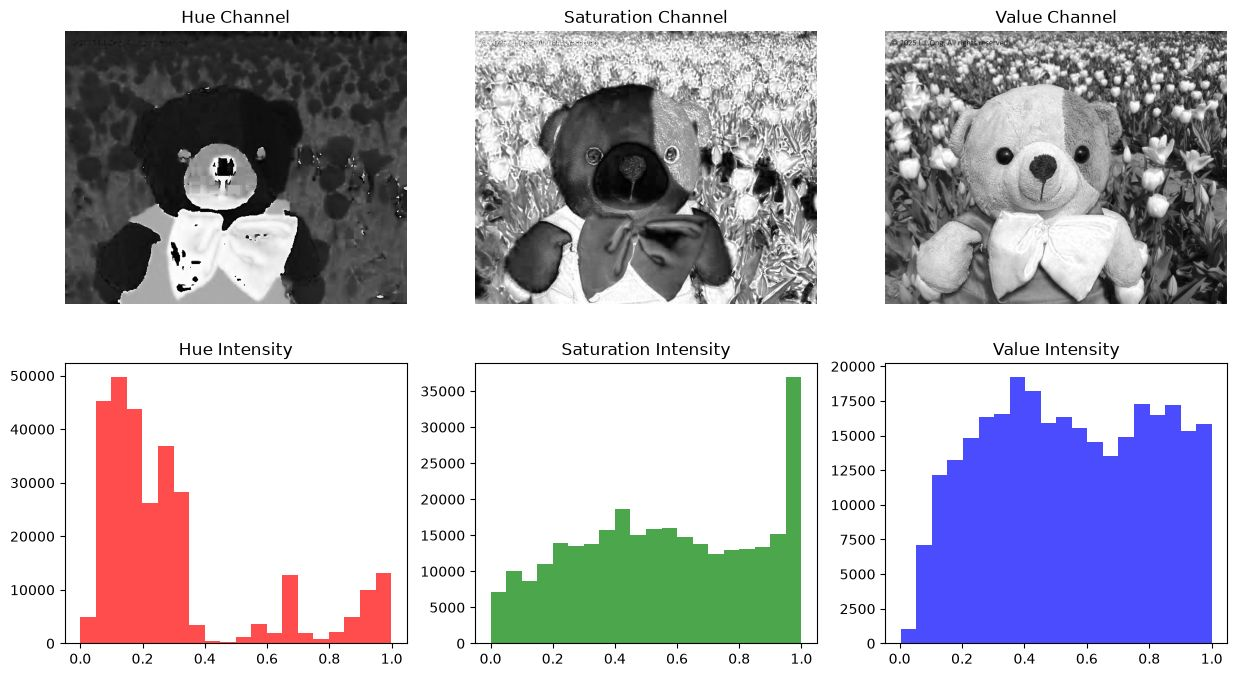

In [5]:
# Convert to HSV and separate the H, S and V channels
hsv_im = color.rgb2hsv(im) 
h_im = hsv_im[:,:,0]
s_im = hsv_im[:,:,1]
v_im = hsv_im[:,:,2]

# Display three channels separately in subplots with the corresponding intensity histograms
plt.figure(figsize=(15,8))
plt.subplot(2,3,1); plt.imshow(h_im, cmap='gray'); plt.title('Hue Channel'); plt.axis('off')
plt.subplot(2,3,2); plt.imshow(s_im, cmap='gray'); plt.title('Saturation Channel'); plt.axis('off')
plt.subplot(2,3,3); plt.imshow(v_im, cmap='gray'); plt.title('Value Channel'); plt.axis('off')
plt.subplot(2,3,4); plt.hist(h_im.ravel(), bins=20, color='r', alpha=0.7); plt.title('Hue Intensity')
plt.subplot(2,3,5); plt.hist(s_im.ravel(), bins=20, color='g', alpha=0.7); plt.title('Saturation Intensity')
plt.subplot(2,3,6); plt.hist(v_im.ravel(), bins=20, color='b', alpha=0.7); plt.title('Value Intensity')

plt.show()

### Teddy bear mask

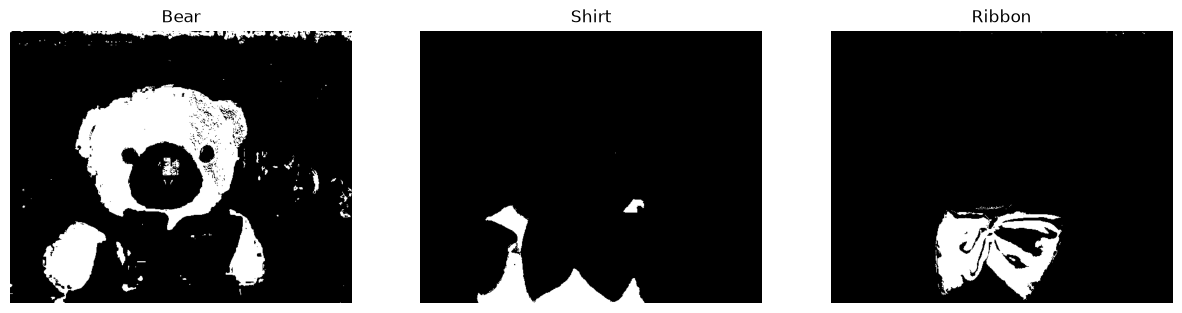

In [6]:
from scipy.ndimage import binary_fill_holes
from skimage.morphology import binary_closing, binary_erosion, binary_opening, disk, remove_small_objects

# HSV ranges for the bear, its shirt and its ribbon
bear = (h_im > 0.00) & (h_im < 0.12) & (s_im < 0.80) & (v_im > 0.15)
shirt = (h_im > 0.55) & (h_im < 0.70) & (s_im > 0.4) & (v_im > 0.2)
tie = ((h_im > 0.80) | (h_im < 0.05)) & (s_im > 0.3) & (v_im > 0.7)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1); plt.imshow(bear, cmap="gray"); plt.title("Bear"); plt.axis("off")
plt.subplot(1, 3, 2); plt.imshow(shirt, cmap="gray"); plt.title("Shirt"); plt.axis("off")
plt.subplot(1, 3, 3); plt.imshow(tie, cmap="gray"); plt.title("Ribbon"); plt.axis("off")
plt.show()

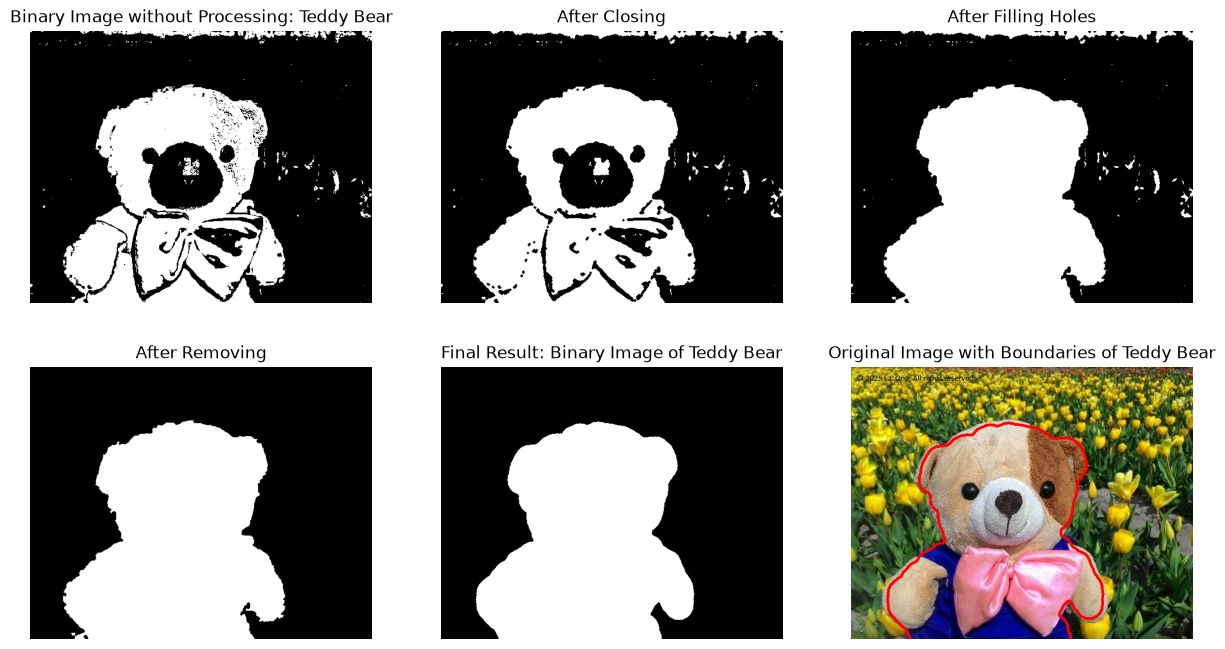

In [7]:
teddy = bear | shirt | tie

# Clean the mask: close small gaps, fill holes, drop small blobs, smooth the outline
teddy_closed = binary_closing(teddy, disk(2))
teddy_filled = binary_fill_holes(teddy_closed)
teddy_removed = remove_small_objects(teddy_filled, min_size=5000)
teddy_pro = binary_opening(teddy_removed, disk(25))

# Red boundary on the original image
teddy_boundary = teddy_pro ^ binary_erosion(teddy_pro, disk(5))
teddy_overlay = im.copy()
teddy_overlay[teddy_boundary] = [255, 0, 0]

plt.figure(figsize=(15, 8))
plt.subplot(2, 3, 1); plt.imshow(teddy, cmap="gray"); plt.title("Binary Image without Processing: Teddy Bear"); plt.axis("off")
plt.subplot(2, 3, 2); plt.imshow(teddy_closed, cmap="gray"); plt.title("After Closing"); plt.axis("off")
plt.subplot(2, 3, 3); plt.imshow(teddy_filled, cmap="gray"); plt.title("After Filling Holes"); plt.axis("off")
plt.subplot(2, 3, 4); plt.imshow(teddy_removed, cmap="gray"); plt.title("After Removing"); plt.axis("off")
plt.subplot(2, 3, 5); plt.imshow(teddy_pro, cmap="gray"); plt.title("Final Result: Binary Image of Teddy Bear"); plt.axis("off")
plt.subplot(2, 3, 6); plt.imshow(teddy_overlay); plt.title("Original Image with Boundaries of Teddy Bear"); plt.axis("off")
plt.show()

### Bounding box of the head

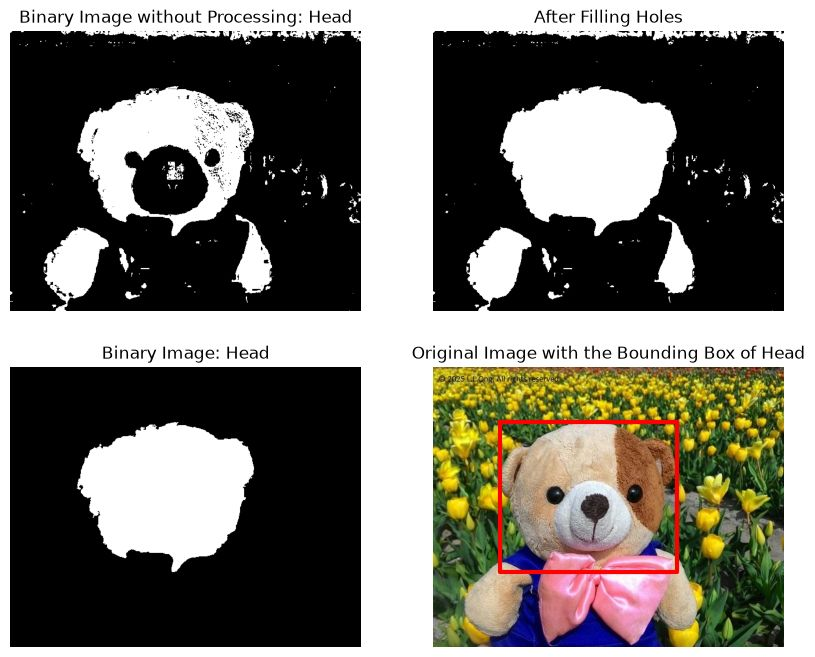

In [8]:
from skimage.measure import label, regionprops

# After removing small objects, the light-brown mask keeps only the bear's head
bear_filled = binary_fill_holes(bear)
bear_pro = remove_small_objects(bear_filled, min_size=10000)

head_region = regionprops(label(bear_pro))[0]
minr, minc, maxr, maxc = head_region.bbox

plt.figure(figsize=(10, 8))
plt.subplot(2, 2, 1); plt.imshow(bear, cmap="gray"); plt.title("Binary Image without Processing: Head"); plt.axis("off")
plt.subplot(2, 2, 2); plt.imshow(bear_filled, cmap="gray"); plt.title("After Filling Holes"); plt.axis("off")
plt.subplot(2, 2, 3); plt.imshow(bear_pro, cmap="gray"); plt.title("Binary Image: Head"); plt.axis("off")
plt.subplot(2, 2, 4)
plt.imshow(im)
plt.plot([minc, maxc, maxc, minc, minc], [minr, minr, maxr, maxr, minr], "-r", linewidth=3)
plt.title("Original Image with the Bounding Box of Head")
plt.axis("off")
plt.show()

### Eyes

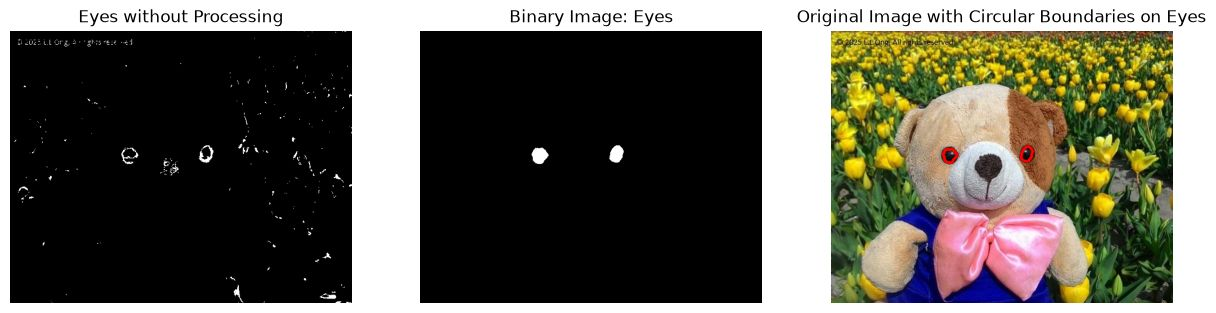

In [9]:
# Eyes: dark pixels with a low hue
eyes = (h_im < 0.20) & (v_im < 0.15)

eyes_pro = binary_closing(eyes, disk(3))
eyes_pro = binary_fill_holes(eyes_pro)
eyes_pro = remove_small_objects(eyes_pro, min_size=500)
eyes_pro = ~binary_opening(~eyes_pro, disk(20))  # opening on the inverted mask rounds the eyes

eyes_boundary = eyes_pro ^ binary_erosion(eyes_pro, disk(5))
eyes_overlay = im.copy()
eyes_overlay[eyes_boundary] = [255, 0, 0]

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1); plt.imshow(eyes, cmap="gray"); plt.title("Eyes without Processing"); plt.axis("off")
plt.subplot(1, 3, 2); plt.imshow(eyes_pro, cmap="gray"); plt.title("Binary Image: Eyes"); plt.axis("off")
plt.subplot(1, 3, 3); plt.imshow(eyes_overlay); plt.title("Original Image with Circular Boundaries on Eyes"); plt.axis("off")
plt.show()

Eye 1:
  Area: 577.0 pixels
  Centroid: (346.84, 218.07)
Eye 2:
  Area: 632.0 pixels
  Centroid: (210.62, 220.66)


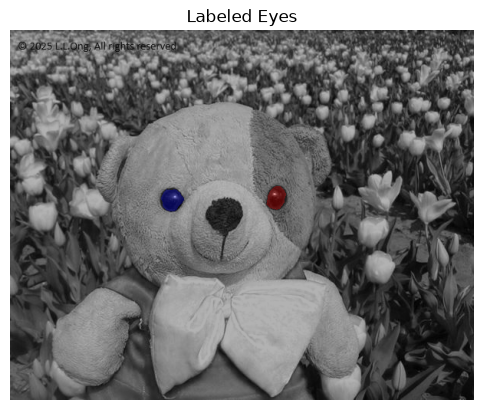

In [10]:
from skimage.color import label2rgb

labeled_eyes = label(eyes_pro)
for i, region in enumerate(regionprops(labeled_eyes), start=1):
    row, col = region.centroid
    print(f"Eye {i}:")
    print(f"  Area: {region.area} pixels")
    print(f"  Centroid: ({col:.2f}, {row:.2f})")

plt.figure()
plt.imshow(label2rgb(labeled_eyes, image=im, bg_label=0))
plt.axis("off")
plt.title("Labeled Eyes")
plt.show()